In [8]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

df = pd.read_csv("dataset_precio_gasolina.csv", parse_dates=["Fecha"])
print(df.shape)
df.head()

(72, 10)


,Fecha,Precio_Gasolina_USD_Galon,Precio_Petroleo_USD_Barril,Tipo_Cambio_USD_COP,Demanda_miles_barriles_dia,Produccion_OPEP_millones_dia,Inflacion_Porcentaje,PIB_Porcentaje,Eventos_Geopoliticos,Impuestos_Combustibles_Porcentaje
0,2018-01-01,8.17,73.94,3683.88,9673.0,27.45,3.84,3.54,1,18
1,2018-02-01,8.51,62.51,4404.09,9819.0,28.53,2.75,5.57,0,22
2,2018-03-01,8.17,76.66,2521.11,9254.0,28.03,3.25,2.28,0,22
3,2018-04-01,9.09,92.41,4069.86,9230.0,29.16,2.91,3.30,0,22
4,2018-05-01,8.10,60.79,3739.17,9746.0,33.63,2.79,3.88,0,18


In [4]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 72 entries, 0 to 71
Data columns (total 10 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   Fecha                              72 non-null     datetime64[us]
 1   Precio_Gasolina_USD_Galon          72 non-null     float64       
 2   Precio_Petroleo_USD_Barril         72 non-null     float64       
 3   Tipo_Cambio_USD_COP                72 non-null     float64       
 4   Demanda_miles_barriles_dia         72 non-null     float64       
 5   Produccion_OPEP_millones_dia       72 non-null     float64       
 6   Inflacion_Porcentaje               72 non-null     float64       
 7   PIB_Porcentaje                     72 non-null     float64       
 8   Eventos_Geopoliticos               72 non-null     int64         
 9   Impuestos_Combustibles_Porcentaje  72 non-null     int64         
dtypes: datetime64[us](1), float64(7), int64(2)
memory u

,Fecha,Precio_Gasolina_USD_Galon,Precio_Petroleo_USD_Barril,Tipo_Cambio_USD_COP,Demanda_miles_barriles_dia,Produccion_OPEP_millones_dia,Inflacion_Porcentaje,PIB_Porcentaje,Eventos_Geopoliticos,Impuestos_Combustibles_Porcentaje
count,72,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000,72.000000
mean,2020-12-15 15:20:00,8.104444,63.117778,3674.238611,9652.069444,28.897778,3.563333,2.779167,0.138889,22.180556
min,2018-01-01 00:00:00,6.560000,29.730000,2521.110000,9176.000000,25.000000,1.760000,-1.750000,0.000000,18.000000
25%,2019-06-23 12:00:00,7.487500,53.247500,3429.897500,9407.500000,27.517500,2.827500,1.225000,0.000000,21.000000
50%,2020-12-16 12:00:00,8.080000,62.085000,3686.225000,9682.500000,28.825000,3.510000,2.735000,0.000000,22.000000
75%,2022-06-08 12:00:00,8.730000,74.147500,3889.645000,9788.000000,30.330000,4.250000,4.405000,0.000000,25.000000
max,2023-12-01 00:00:00,10.500000,98.340000,4808.460000,10679.000000,33.630000,6.010000,6.880000,1.000000,30.000000
std,NaN,0.790899,16.383220,444.171734,270.140304,2.134165,0.883983,2.120914,0.348257,3.229819


In [9]:
print(df.isna().sum())
print("Duplicados:", df.duplicated().sum())

Fecha                                0
Precio_Gasolina_USD_Galon            0
Precio_Petroleo_USD_Barril           0
Tipo_Cambio_USD_COP                  0
Demanda_miles_barriles_dia           0
Produccion_OPEP_millones_dia         0
Inflacion_Porcentaje                 0
PIB_Porcentaje                       0
Eventos_Geopoliticos                 0
Impuestos_Combustibles_Porcentaje    0
dtype: int64
Duplicados: 0


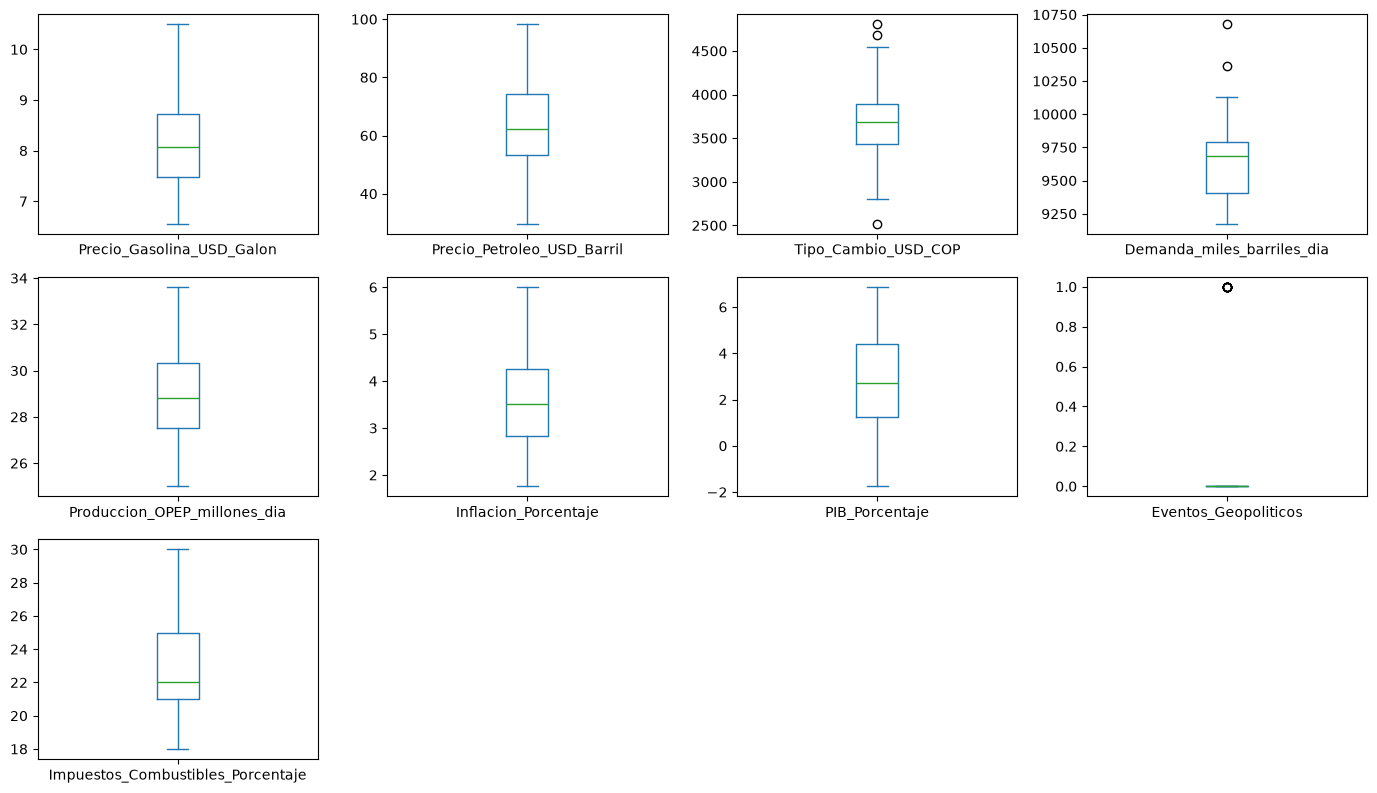

In [10]:
cols_num = df.select_dtypes("number").columns
df[cols_num].plot(kind="box", subplots=True, layout=(3,4), figsize=(14,8))
plt.tight_layout(); plt.show()

In [11]:
for col in cols_num:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_out = ((df[col] < low) | (df[col] > high)).sum()
    print(f"{col}: {n_out} atípicos")
    df[col] = df[col].clip(low, high)

Precio_Gasolina_USD_Galon: 0 atípicos
Precio_Petroleo_USD_Barril: 0 atípicos
Tipo_Cambio_USD_COP: 3 atípicos
Demanda_miles_barriles_dia: 2 atípicos
Produccion_OPEP_millones_dia: 0 atípicos
Inflacion_Porcentaje: 0 atípicos
PIB_Porcentaje: 0 atípicos
Eventos_Geopoliticos: 10 atípicos
Impuestos_Combustibles_Porcentaje: 0 atípicos


In [12]:
print(df["Eventos_Geopoliticos"].value_counts())

Eventos_Geopoliticos
0    72
Name: count, dtype: int64


In [13]:
df = pd.read_csv("dataset_precio_gasolina.csv", parse_dates=["Fecha"])

cols_num = df.select_dtypes("number").columns
excluir = ["Eventos_Geopoliticos"]      # variable discreta: no se recorta

for col in cols_num:
    if col in excluir:
        continue
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5*iqr, q3 + 1.5*iqr
    df[col] = df[col].clip(low, high)

print(df["Eventos_Geopoliticos"].value_counts())

Eventos_Geopoliticos
0    62
1    10
Name: count, dtype: int64


In [14]:
target = "Precio_Gasolina_USD_Galon"
features = ["Precio_Petroleo_USD_Barril", "Tipo_Cambio_USD_COP",
            "Demanda_miles_barriles_dia", "Produccion_OPEP_millones_dia",
            "Inflacion_Porcentaje", "PIB_Porcentaje",
            "Eventos_Geopoliticos", "Impuestos_Combustibles_Porcentaje"]

X = df[features]
y = df[target]
print(X.shape, y.shape)

(72, 8) (72,)


In [15]:
target = "Precio_Gasolina_USD_Galon"
features = ["Precio_Petroleo_USD_Barril", "Tipo_Cambio_USD_COP",
            "Demanda_miles_barriles_dia", "Produccion_OPEP_millones_dia",
            "Inflacion_Porcentaje", "PIB_Porcentaje",
            "Eventos_Geopoliticos", "Impuestos_Combustibles_Porcentaje"]

X = df[features]
y = df[target]
print(X.shape, y.shape)

(72, 8) (72,)


In [16]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.35, random_state=42)
print(X_train.shape, X_test.shape)

(46, 8) (26, 8)


In [17]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=features, index=X_train.index)
X_test_s  = pd.DataFrame(scaler.transform(X_test),  columns=features, index=X_test.index)

In [18]:
import statsmodels.api as sm

Xc = sm.add_constant(X_train_s)
ols = sm.OLS(y_train, Xc).fit()
print(ols.summary())

                                OLS Regression Results                               
Dep. Variable:     Precio_Gasolina_USD_Galon   R-squared:                       0.926
Model:                                   OLS   Adj. R-squared:                  0.910
Method:                        Least Squares   F-statistic:                     57.72
Date:                       Tue, 13 Oct 2026   Prob (F-statistic):           1.45e-18
Time:                               20:07:07   Log-Likelihood:                 5.6003
No. Observations:                         46   AIC:                             6.799
Df Residuals:                             37   BIC:                             23.26
Df Model:                                  8                                         
Covariance Type:                   nonrobust                                         
                                        coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------

In [19]:
sel = features.copy()
while True:
    m = sm.OLS(y_train, sm.add_constant(X_train_s[sel])).fit()
    pvals = m.pvalues.drop("const")
    if pvals.max() > 0.05:
        quitar = pvals.idxmax()
        print("Se elimina:", quitar, "p =", round(pvals.max(), 3))
        sel.remove(quitar)
    else:
        break
print("Variables finales:", sel)
print(m.summary())

Se elimina: Produccion_OPEP_millones_dia p = 0.952
Variables finales: ['Precio_Petroleo_USD_Barril', 'Tipo_Cambio_USD_COP', 'Demanda_miles_barriles_dia', 'Inflacion_Porcentaje', 'PIB_Porcentaje', 'Eventos_Geopoliticos', 'Impuestos_Combustibles_Porcentaje']
                                OLS Regression Results                               
Dep. Variable:     Precio_Gasolina_USD_Galon   R-squared:                       0.926
Model:                                   OLS   Adj. R-squared:                  0.912
Method:                        Least Squares   F-statistic:                     67.74
Date:                       Tue, 13 Oct 2026   Prob (F-statistic):           1.69e-19
Time:                               20:09:28   Log-Likelihood:                 5.5980
No. Observations:                         46   AIC:                             4.804
Df Residuals:                             38   BIC:                             19.43
Df Model:                                  7           

In [20]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

X_train_f, X_test_f = X_train[sel], X_test[sel]
scaler_f = StandardScaler().fit(X_train_f)
Xtr = scaler_f.transform(X_train_f)
Xte = scaler_f.transform(X_test_f)

modelo = LinearRegression().fit(Xtr, y_train)

pred_train = modelo.predict(Xtr)
pred_test  = modelo.predict(Xte)

mse  = mean_squared_error(y_test, pred_test)
rmse = np.sqrt(mse)
mae  = mean_absolute_error(y_test, pred_test)
r2   = r2_score(y_test, pred_test)

print(f"R² entrenamiento: {r2_score(y_train, pred_train):.4f}")
print(f"R² prueba:        {r2:.4f}")
print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")

R² entrenamiento: 0.9258
R² prueba:        0.8431
MAE:  0.2570
MSE:  0.0956
RMSE: 0.3091


In [21]:
print(pd.Series(modelo.coef_, index=sel).sort_values(key=abs, ascending=False))

Precio_Petroleo_USD_Barril           0.638221
PIB_Porcentaje                       0.284993
Impuestos_Combustibles_Porcentaje    0.231185
Eventos_Geopoliticos                 0.167212
Inflacion_Porcentaje                -0.154807
Tipo_Cambio_USD_COP                  0.077960
Demanda_miles_barriles_dia           0.076518
dtype: float64


In [22]:
from scipy import stats

res_train = y_train - modelo.predict(Xtr)
n, p = Xtr.shape
dof = n - p - 1
s = np.sqrt((res_train**2).sum() / dof)   # error estándar de los residuos
t = stats.t.ppf(0.975, dof)               # ≈ 2.02 para el 95%

def predecir(valores: dict):
    x = scaler_f.transform(pd.DataFrame([valores])[sel])
    pred = modelo.predict(x)[0]
    return pred, pred - t*s, pred + t*s

ejemplo = {c: X_train[c].mean() for c in sel}
pred, lo, hi = predecir(ejemplo)
print(f"Precio estimado: {pred:.2f} USD/galón")
print(f"IC 95%: [{lo:.2f} ; {hi:.2f}]")

Precio estimado: 8.07 USD/galón
IC 95%: [7.60 ; 8.55]


In [23]:
import joblib

joblib.dump({
    "modelo": modelo, "scaler": scaler_f, "features": sel,
    "s": s, "t": t,
    "medias": X_train[sel].mean().to_dict(),
    "minimos": X[sel].min().to_dict(),
    "maximos": X[sel].max().to_dict(),
    "metricas": {"R2_prueba": r2, "MAE": mae, "MSE": mse, "RMSE": rmse},
}, "modelo_gasolina.pkl")

print("Modelo guardado")

Modelo guardado
